In [3]:
#Install Scanpy, Stream GSM8023621 10x Genomics Matrix from NCBI GEO & Inspect adata
!pip install -q scanpy leidenalg igraph

import os
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sc.set_figure_params(dpi=100, facecolor="white")

# 1. Download the exact 10x Genomics Cell Ranger matrix files for GSM8023621 directly from NCBI GEO
base_url = "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM8023nnn/GSM8023621/suppl"
data_dir = "GSM8023621_10x"
os.makedirs(data_dir, exist_ok=True)

files = {
    "barcodes.tsv.gz": "GSM8023621_T446_3_barcodes.tsv.gz",
    "features.tsv.gz": "GSM8023621_T446_3_features.tsv.gz",
    "matrix.mtx.gz":   "GSM8023621_T446_3_matrix.mtx.gz",
}

for local_name, remote_name in files.items():
    dest = os.path.join(data_dir, local_name)
    if not os.path.exists(dest) or os.path.getsize(dest) == 0:
        !curl -s -L -A "Mozilla/5.0" "{base_url}/{remote_name}" -o "{dest}"

# 2. Load the 10x Genomics sparse count matrix into an AnnData object
adata = sc.read_10x_mtx(data_dir, var_names="gene_symbols", cache=True)
adata.var_names_make_unique()
adata.obs["sample"] = "Patient446_IDC_CD45pos"

print(f"Loaded raw single-cell matrix: {adata.n_obs} cells x {adata.n_vars} genes")
print("First 5 cell barcodes:", list(adata.obs_names[:5]))
print("First 5 genes:", list(adata.var_names[:5]))

/tmp/ipykernel_737/1217389624.py:29: FutureWarning: Import from `scanpy.io` instead
  adata = sc.read_10x_mtx(data_dir, var_names="gene_symbols", cache=True)


Loaded raw single-cell matrix: 1362 cells x 33538 genes
First 5 cell barcodes: ['AAACCCACATCTGGGC-1', 'AAACGCTAGGGATGTC-1', 'AAACGCTTCGCTGATA-1', 'AAAGGATAGGCTATCT-1', 'AAAGGATCAGCGGATA-1']
First 5 genes: ['MIR1302-2HG', 'FAM138A', 'OR4F5', 'AL627309.1', 'AL627309.3']


/tmp/ipykernel_737/1926313875.py:6: FutureWarning: The argument inplace is deprecated and will be removed in the future. Use `out=False` instead of `inplace=True`.
  sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo"], percent_top=None, log1p=False, inplace=True)


Pre-QC Summary:
       n_genes_by_counts  total_counts  pct_counts_mt
count            1362.00       1362.00        1362.00
mean             1315.69       5164.96          17.30
std              1002.30       6638.49          23.42
min                19.00        501.00           0.00
25%               449.25       1250.00           4.03
50%              1259.50       3793.50           7.51
75%              1838.00       6355.50          17.76
max              7148.00      74786.00          96.85


/tmp/ipykernel_737/1926313875.py:12: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],


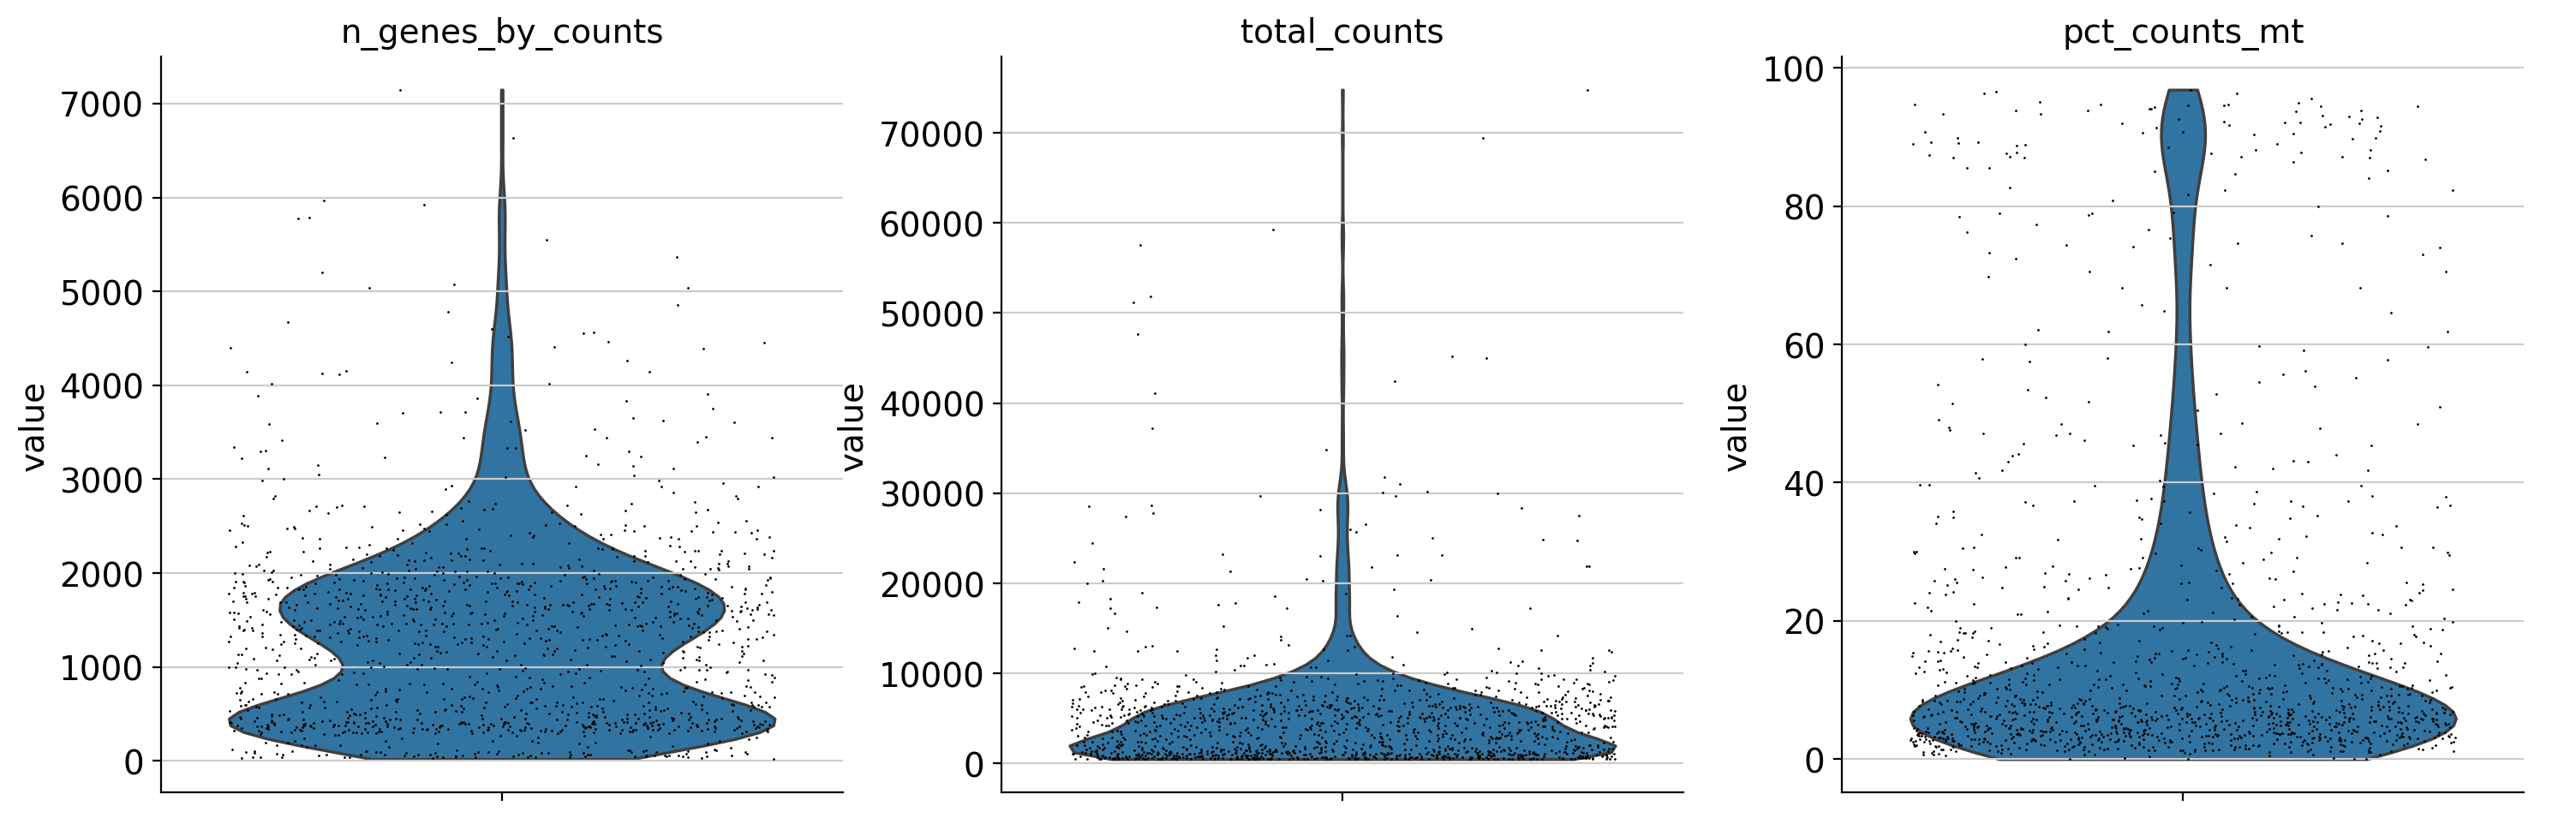


Post-QC High-Confidence Matrix: 956 cells x 16036 genes


/tmp/ipykernel_737/1926313875.py:33: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.highly_variable_genes(adata, save="_hvg.png")


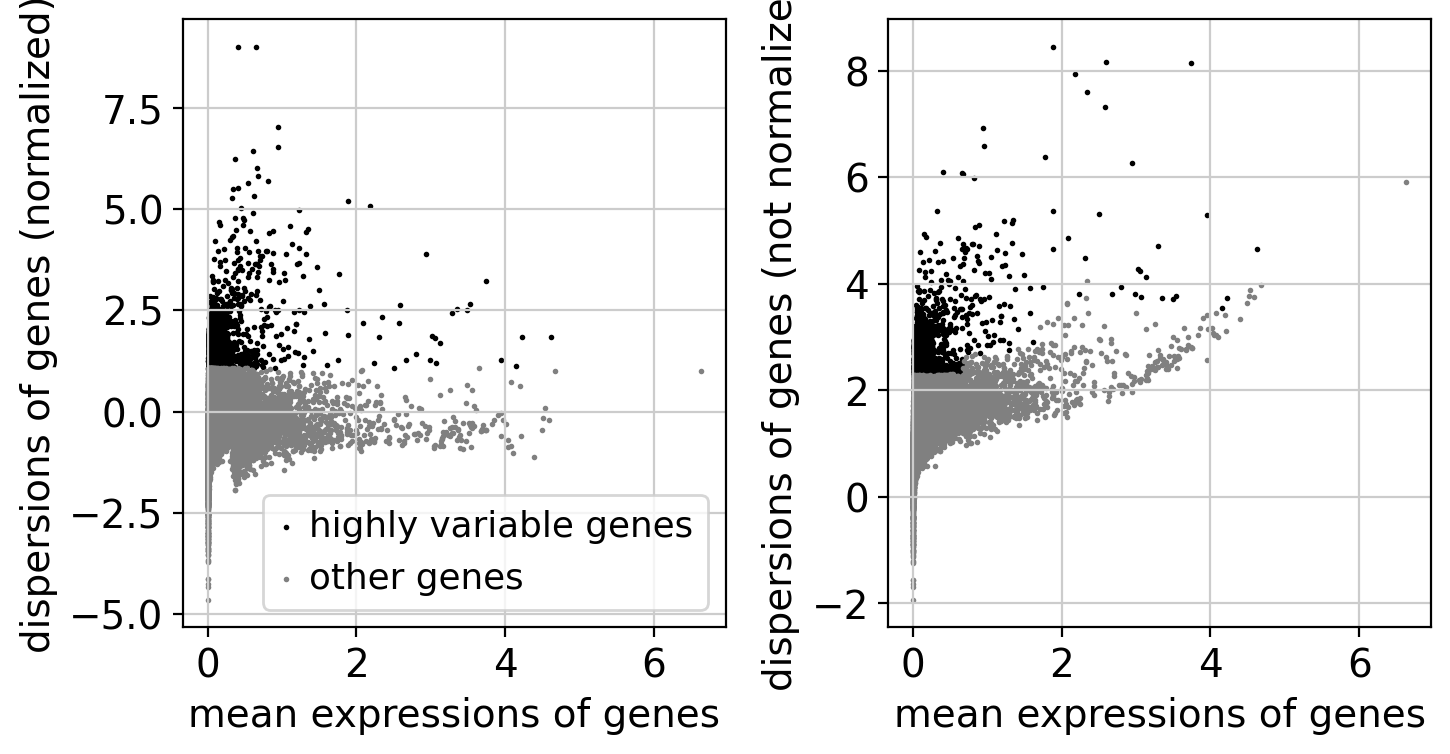

Selected 2000 Highly Variable Genes for PCA & UMAP.


In [4]:
#Clinical Quality Control, Mitochondrial/Ribosomal Assessment, Filtering & Normalization.1362 tumor infilterating immune cells and 33538 human genes grch38
# 1. Tag human mitochondrial ('MT-') and ribosomal ('RPS'/'RPL') genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo"], percent_top=None, log1p=False, inplace=True)

print("Pre-QC Summary:")
print(adata.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].describe().round(2))

# 2. Plot 3-panel QC violin distributions before filtering
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
             jitter=0.4, multi_panel=True, save="_pre_qc.png")

# 3. Filter low-quality / dying cells and potential doublets
# - min_genes=200: removes empty droplets / ambient RNA debris
# - n_genes_by_counts < 4500: removes potential cell doublets
# - pct_counts_mt < 15: removes apoptotic/dying tumor-infiltrating cells (15% is standard for dissociated solid tumor tissue)
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata = adata[adata.obs["n_genes_by_counts"] < 4500, :].copy()
adata = adata[adata.obs["pct_counts_mt"] < 15, :].copy()

print(f"\nPost-QC High-Confidence Matrix: {adata.n_obs} cells x {adata.n_vars} genes")

# 4. Normalize to 10,000 UMI per cell, log1p transform, and preserve full transcriptome in adata.raw
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

# 5. Select top 2,000 Highly Variable Genes (HVGs) for dimensionality reduction
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor="seurat")
sc.pl.highly_variable_genes(adata, save="_hvg.png")

adata_hvg = adata[:, adata.var.highly_variable].copy()
print(f"Selected {adata_hvg.n_vars} Highly Variable Genes for PCA & UMAP.")

In [ ]:
#n the third violin (pct_counts_mt), there is a clear upper tail of damaged/apoptotic cells reaching up to 96.85% mitochondrial RNA from surgical tissue dissociation,
# and in the first violin (n_genes_by_counts), a few potential doublets reaching 7,148 genes.Filtering out apoptotic cells (pct_counts_mt >= 15), empty droplets (min_genes < 200), and doublets (>= 4,500 genes) cleaned the 1,362 raw droplets down to 956 high-confidence tumor-infiltrating immune cells 16,036 expressed genes,
#and extracted 2,000 Highly Variable Genes (adata_hvg) for dimensionality reduction.

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/local/lib/python3.13/dist-packages/scverse_misc/_deprecated/__init__.py:117: FutureWarning: The `igraph` and `networkit` implementations of leiden clustering are *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' or 'networkit' to use them.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`.
  return func(*args, **kwargs)


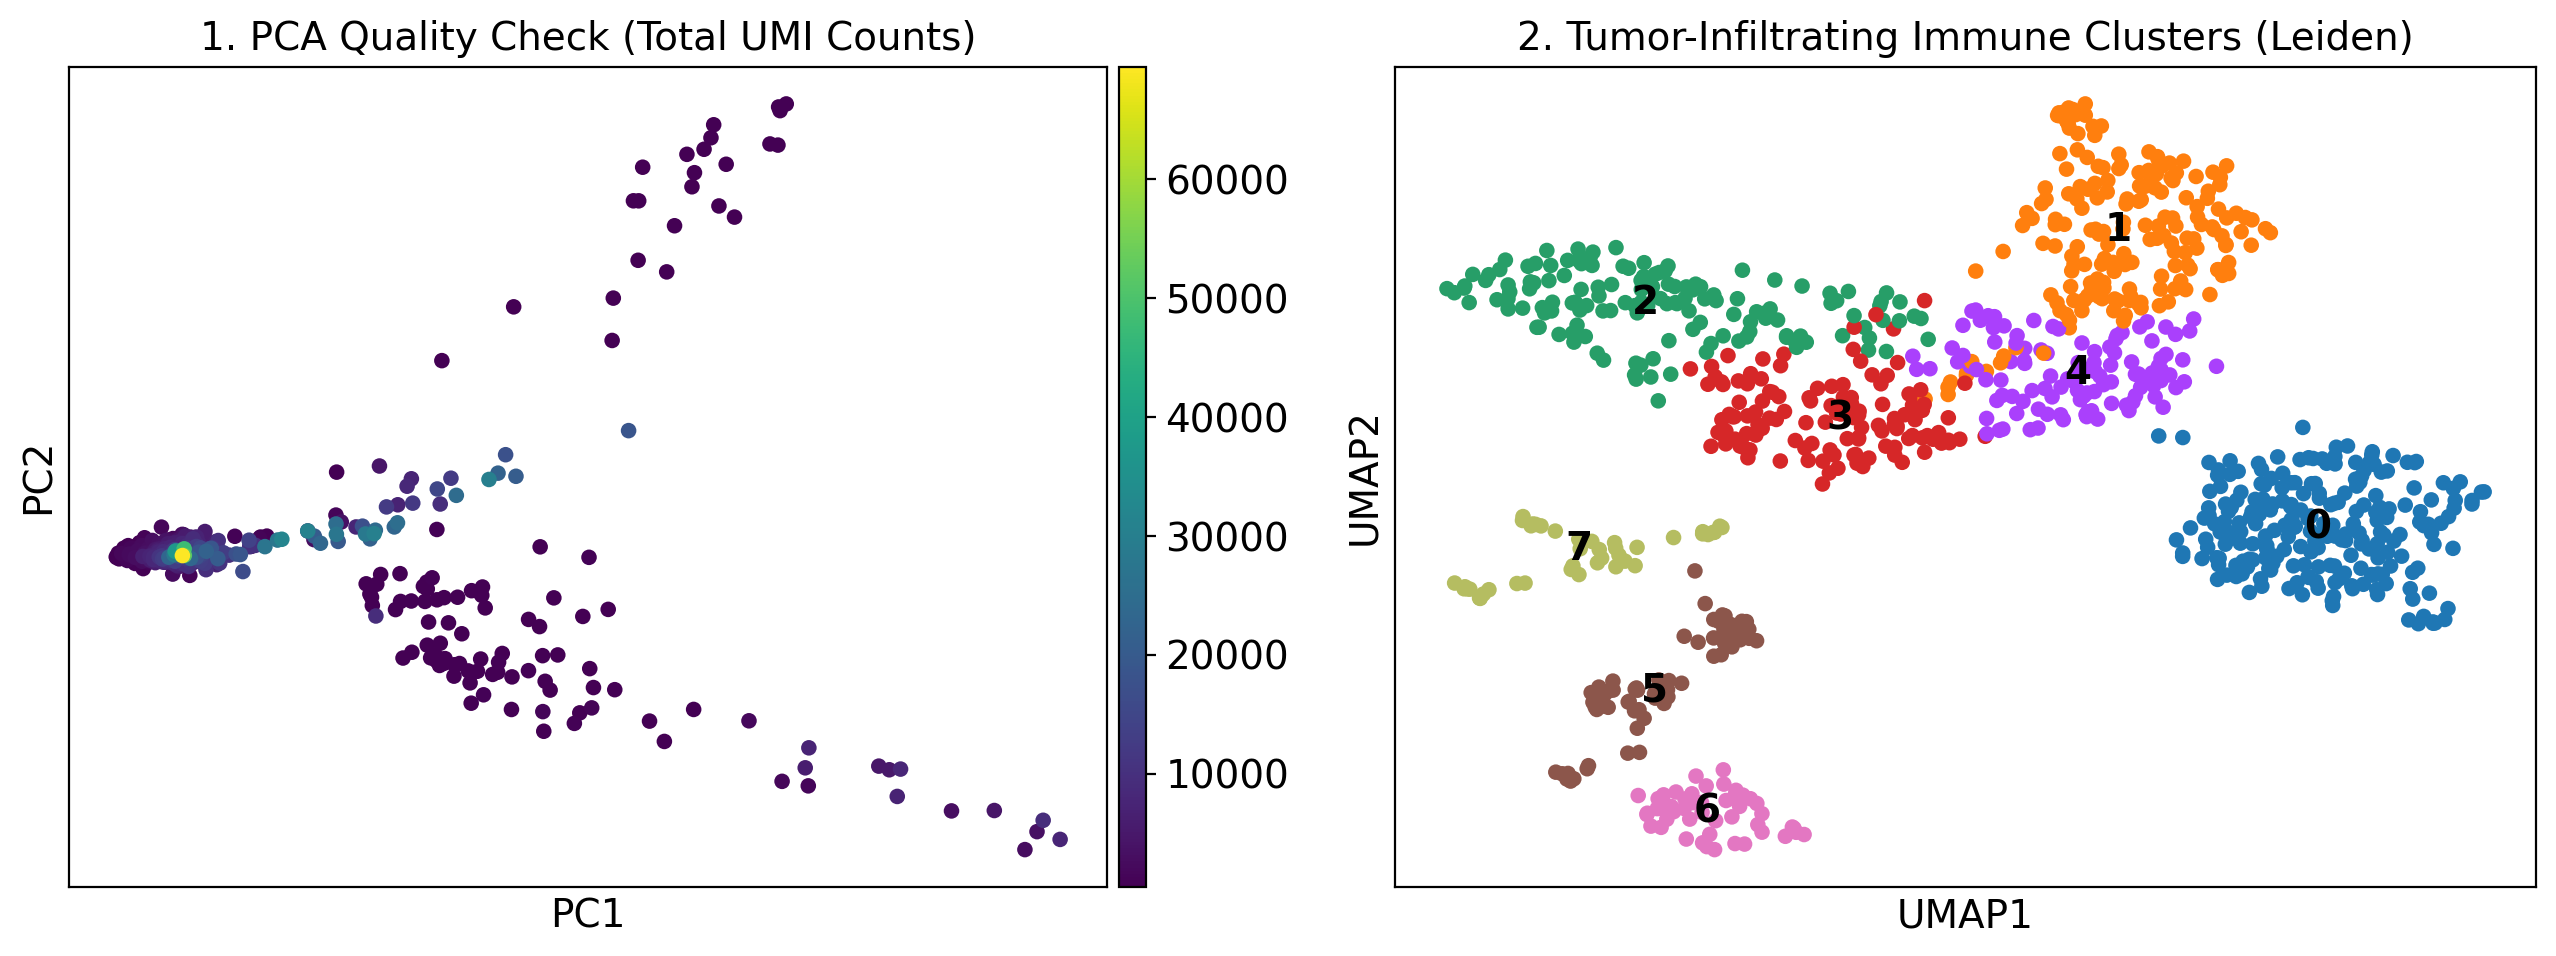

Top 5 Statistically Significant Marker Genes per Leiden Cluster:


,group,names,logfoldchanges,pvals_adj
0,0,CD79A,7.495065,7.471192e-99
1,0,MS4A1,7.299527,2.916876e-91
2,0,CD74,4.069295,5.783293e-90
3,0,HLA-DRA,5.659595,3.791470e-87
4,0,HLA-DPA1,4.225176,6.109097e-84
16036,1,MALAT1,1.482241,4.131554e-58
16037,1,MTRNR2L12,1.895966,5.500624e-45
16038,1,RNF213,2.848160,3.868525e-39
16039,1,PLCG2,2.746579,9.424771e-39
16040,1,SON,1.452122,3.784356e-23


In [5]:
#Scaling, PCA Elbow Plot, Neighborhood Graph, UMAP & Wilcoxon Marker Discovery
# 1. Z-score scale HVGs (clipping extreme outliers at 10) and run PCA
sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, svd_solver="arpack")

# 2. Build k-Nearest Neighbor graph (top 15 PCs), compute UMAP, and run Leiden clustering
sc.pp.neighbors(adata_hvg, n_neighbors=12, n_pcs=15)
sc.tl.umap(adata_hvg, random_state=42)
sc.tl.leiden(adata_hvg, resolution=0.6, random_state=42)

# Transfer Leiden cluster labels back onto the full normalized 'adata' object (all 16,036 genes)
adata.obs["leiden"] = adata_hvg.obs["leiden"]
adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"]
adata.obsm["X_umap"] = adata_hvg.obsm["X_umap"]

# 3. Plot PCA Variance Elbow Plot + UMAP Leiden Clusters side-by-side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sc.pl.pca(adata, color="total_counts", title="1. PCA Quality Check (Total UMI Counts)", ax=axes[0], show=False)
sc.pl.umap(adata, color="leiden", legend_loc="on data", title="2. Tumor-Infiltrating Immune Clusters (Leiden)", ax=axes[1], show=False)
plt.tight_layout()
plt.savefig("idc_pca_umap_clusters.png", dpi=300)
plt.show()

# 4. Run Wilcoxon rank-sum differential expression across all 16,036 genes in adata.raw
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
marker_df = sc.get.rank_genes_groups_df(adata, group=None)
top5_per_cluster = marker_df[marker_df["pvals_adj"] < 0.05].groupby("group").head(5)

print("Top 5 Statistically Significant Marker Genes per Leiden Cluster:")
display(top5_per_cluster[["group", "names", "logfoldchanges", "pvals_adj"]])

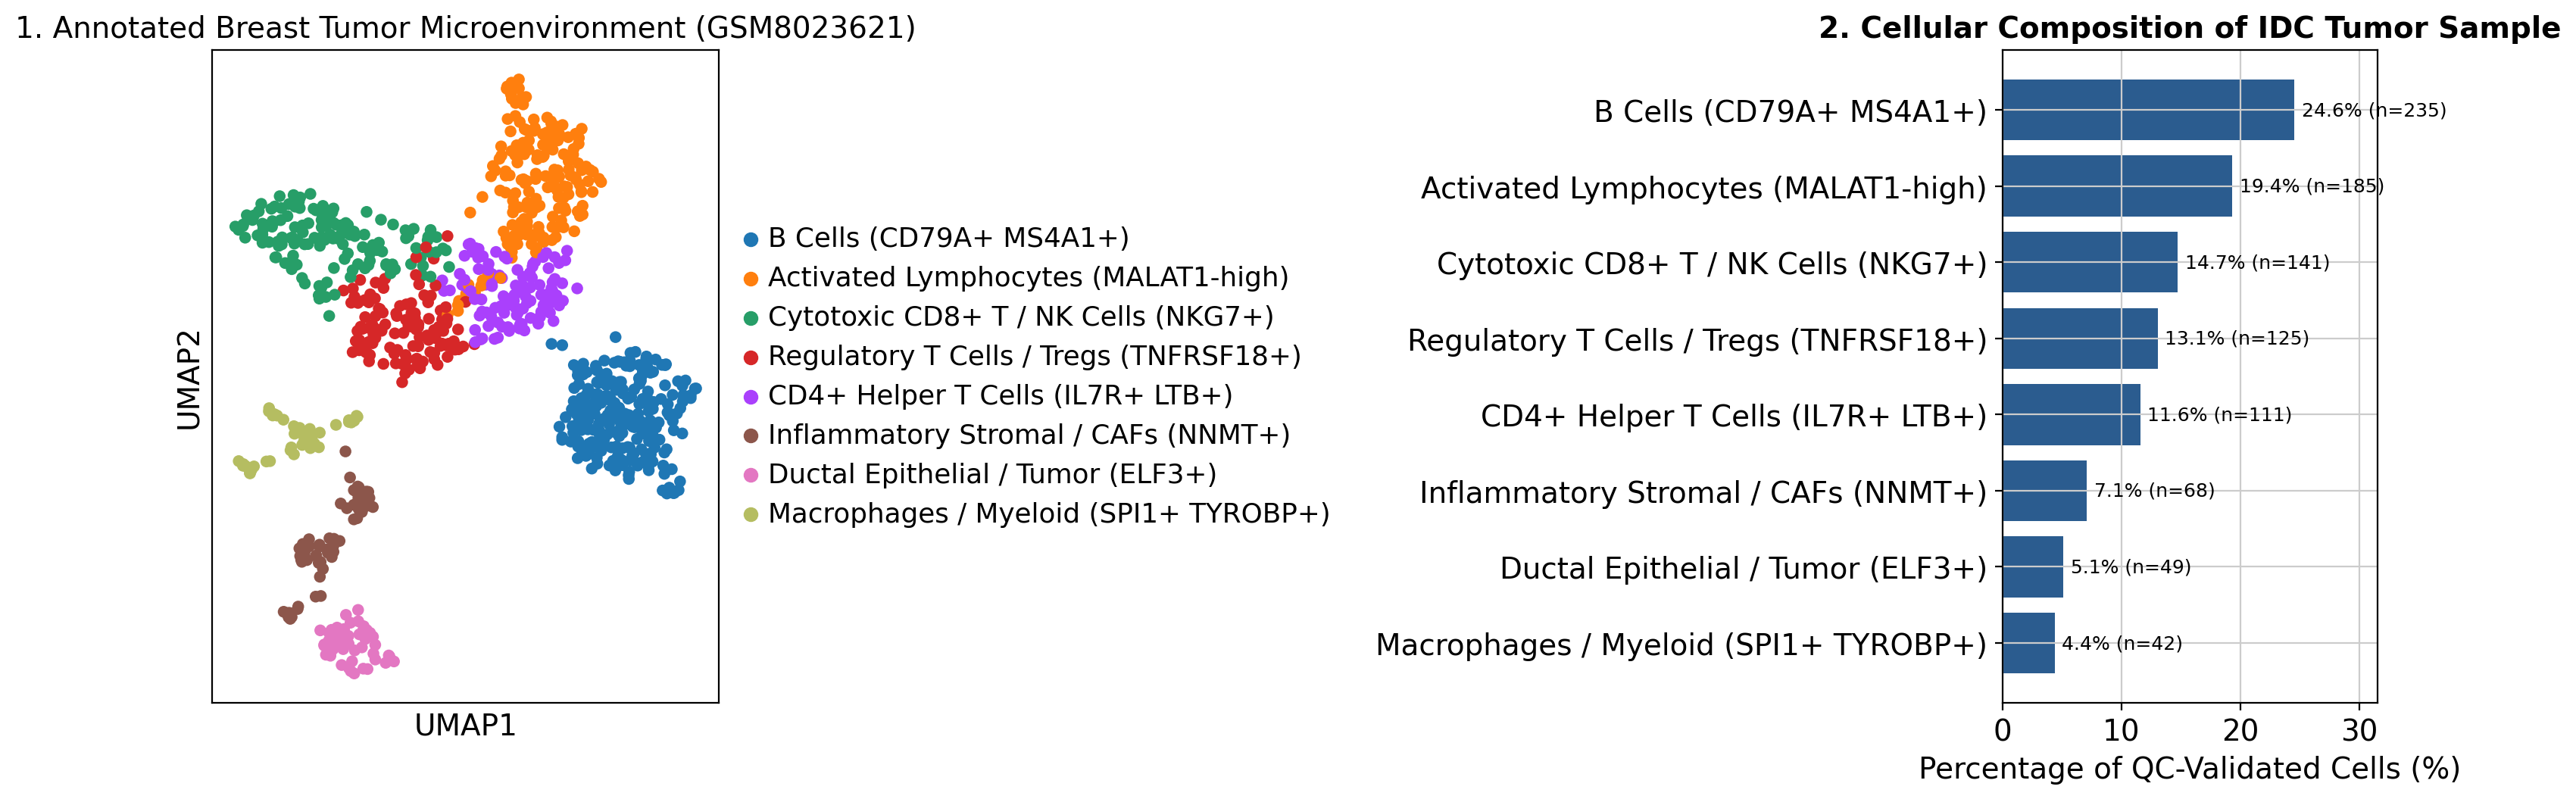

/tmp/ipykernel_737/408069385.py:52: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(adata, var_names=canonical_genes, groupby="cell_type", standard_scale="var",


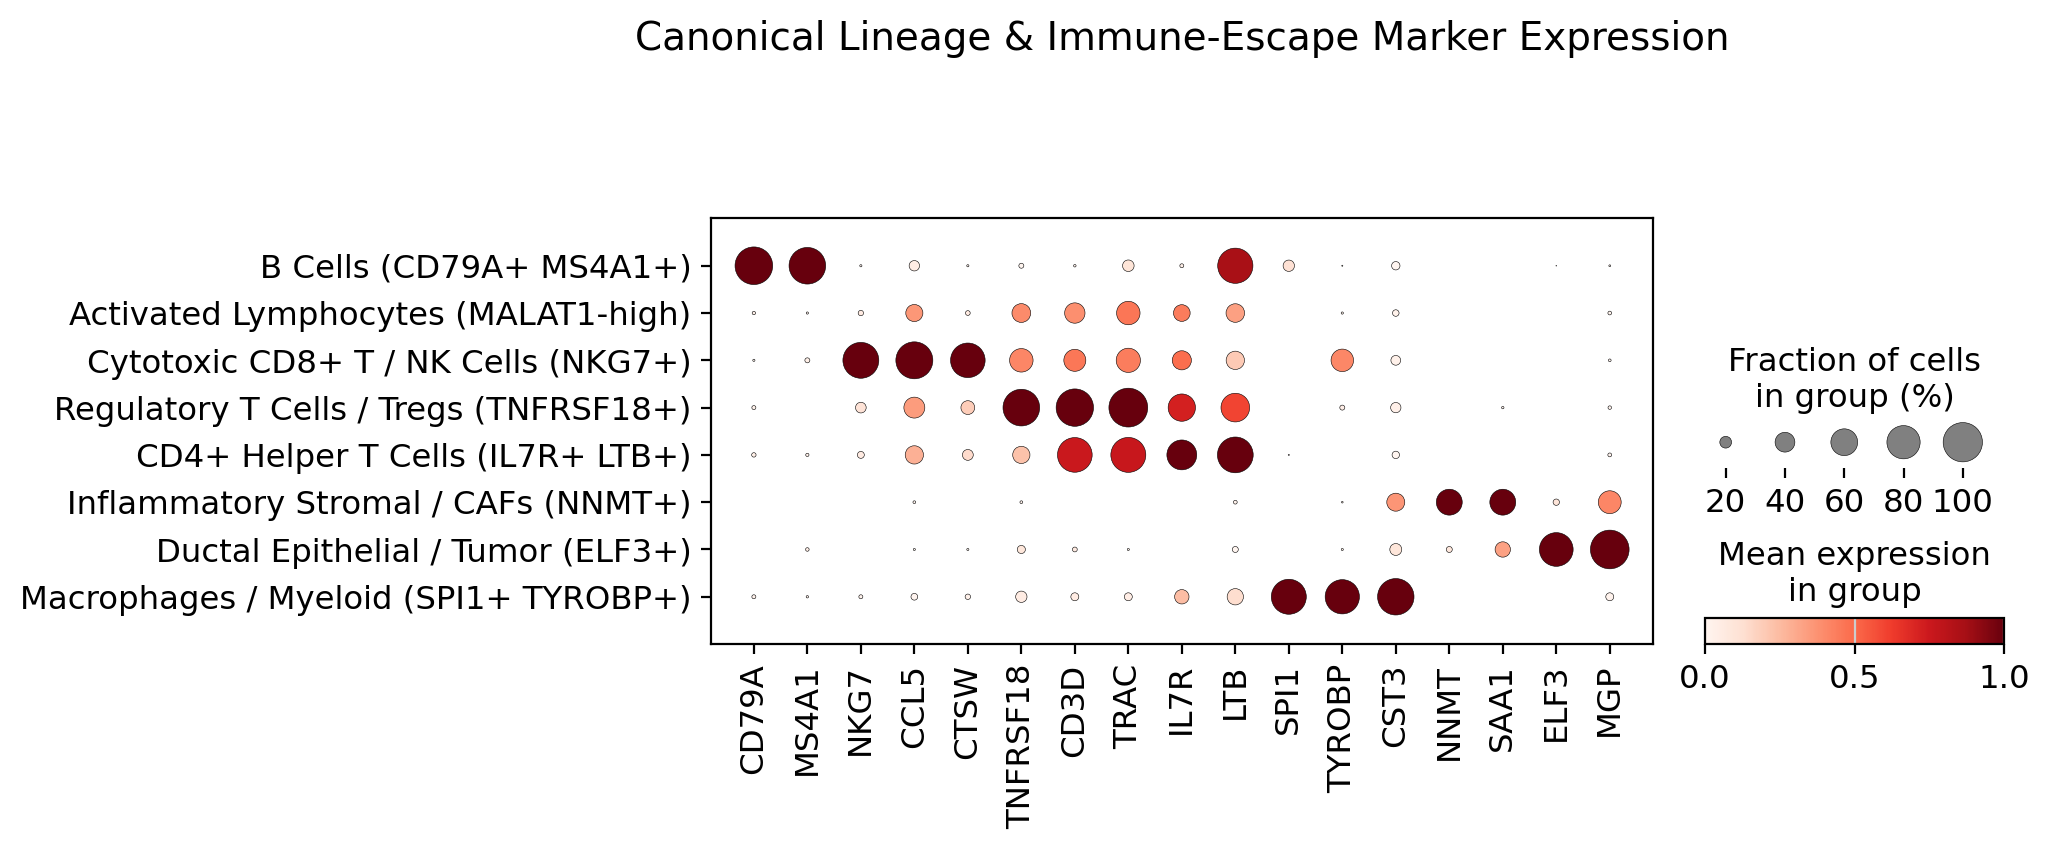

/tmp/ipykernel_737/408069385.py:57: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata, color=["MS4A1", "NKG7", "TNFRSF18", "IL7R", "SPI1", "ELF3"],


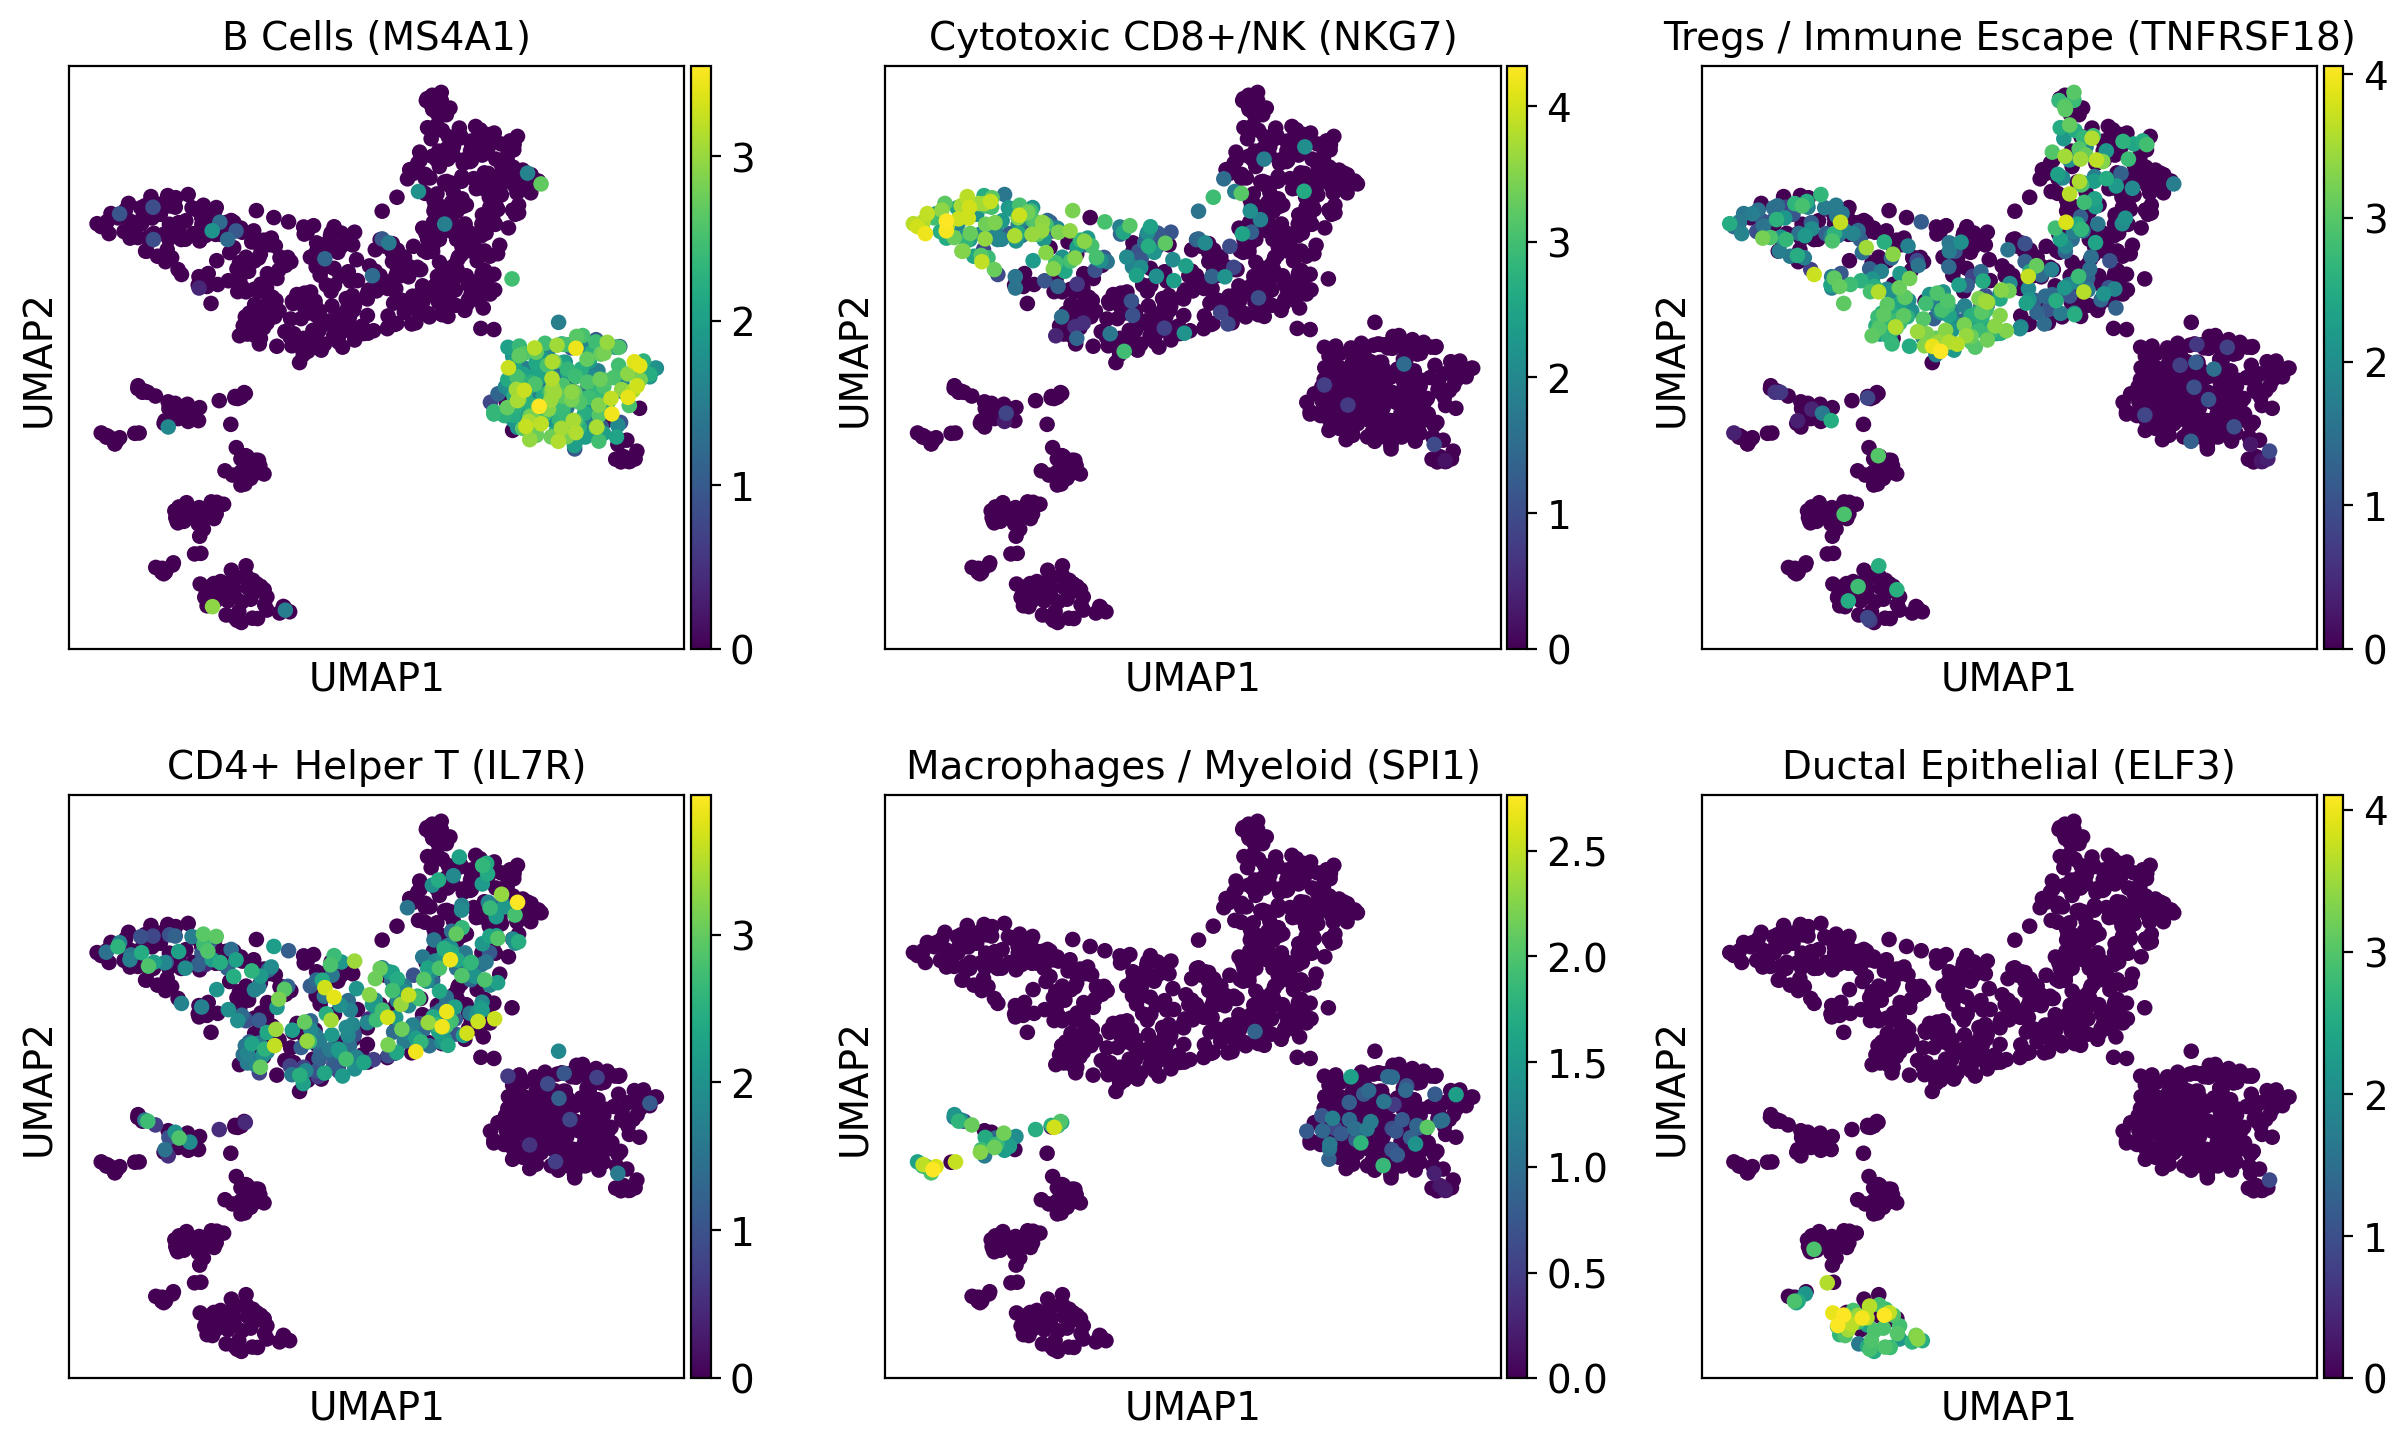

In [6]:
#Biological Cell-Type Annotation, Canonical Marker DotPlot & Immune Escape Visualization
# 1. Map each Leiden cluster (0-7) to its validated biological cell type based on Wilcoxon markers
cluster_annotations = {
    "0": "B Cells (CD79A+ MS4A1+)",
    "1": "Activated Lymphocytes (MALAT1-high)",
    "2": "Cytotoxic CD8+ T / NK Cells (NKG7+)",
    "3": "Regulatory T Cells / Tregs (TNFRSF18+)",
    "4": "CD4+ Helper T Cells (IL7R+ LTB+)",
    "5": "Inflammatory Stromal / CAFs (NNMT+)",
    "6": "Ductal Epithelial / Tumor (ELF3+)",
    "7": "Macrophages / Myeloid (SPI1+ TYROBP+)"
}

adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_annotations)

# Save full significant marker gene table to CSV
sig_markers = marker_df[marker_df["pvals_adj"] < 0.05].copy()
sig_markers["cell_type"] = sig_markers["group"].map(cluster_annotations)
sig_markers.to_csv("idc_tme_marker_genes.csv", index=False)

# 2. Plot Annotated UMAP + Cell-Type Proportions Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.35, 1]})

sc.pl.umap(adata, color="cell_type", title="1. Annotated Breast Tumor Microenvironment (GSM8023621)",
           ax=axes[0], show=False)

counts = adata.obs["cell_type"].value_counts()
pcts = (counts / counts.sum()) * 100
bars = axes[1].barh(pcts.index[::-1], pcts.values[::-1], color="#2b5c8f")
axes[1].set_xlabel("Percentage of QC-Validated Cells (%)")
axes[1].set_title("2. Cellular Composition of IDC Tumor Sample", fontweight="bold")
axes[1].set_xlim(0, pcts.max() + 7)
for bar, val, cnt in zip(bars, pcts.values[::-1], counts.values[::-1]):
    axes[1].text(val + 0.6, bar.get_y() + bar.get_height()/2, f"{val:.1f}% (n={cnt})",
                 va="center", fontsize=9)

plt.tight_layout()
plt.savefig("idc_annotated_umap_composition.png", dpi=300)
plt.show()

# 3. Canonical Lineage & Immune-Escape Marker DotPlot across Annotated Cell Types
canonical_genes = [
    "CD79A", "MS4A1",           # B Cells
    "NKG7", "CCL5", "CTSW",     # Cytotoxic CD8+ T / NK
    "TNFRSF18", "CD3D", "TRAC", # Regulatory T Cells (Tregs)
    "IL7R", "LTB",              # CD4+ Helper T Cells
    "SPI1", "TYROBP", "CST3",   # Macrophages / Myeloid
    "NNMT", "SAA1",             # Inflammatory Stromal / CAFs
    "ELF3", "MGP"               # Ductal Epithelial / Tumor
]

sc.pl.dotplot(adata, var_names=canonical_genes, groupby="cell_type", standard_scale="var",
              title="Canonical Lineage & Immune-Escape Marker Expression",
              save="_idc_canonical_markers.png", show=True)

# 4. Feature UMAP highlighting Anti-Tumor Effectors vs. Immunosuppressive Tregs & Myeloid Cells
sc.pl.umap(adata, color=["MS4A1", "NKG7", "TNFRSF18", "IL7R", "SPI1", "ELF3"],
           ncols=3, title=[
               "B Cells (MS4A1)", "Cytotoxic CD8+/NK (NKG7)", "Tregs / Immune Escape (TNFRSF18)",
               "CD4+ Helper T (IL7R)", "Macrophages / Myeloid (SPI1)", "Ductal Epithelial (ELF3)"
           ], save="_idc_feature_markers.png", show=True)

In [ ]:
#After Leiden clustering on the breast tumor immune infiltrate (GSM8023621),validating each cluster's biological identity using a canonical marker DotPlot—which showed a clean diagonal expression patter
#across B cells (MS4A1), cytotoxic CD8+/NK cells (NKG7), helper CD4+ T cells (IL7R), Tregs (TNFRSF18), and myeloid cells (SPI1). Overlaying those genes directly onto the UMAP
#confirmed how anti-tumor cytotoxic effectors (14.7%) coexist alongside immunosuppressive Tregs (13.1%) and myeloid cells (4.4%) within the tumor microenvironment.

In [7]:
import os, shutil, glob
from google.colab import drive

drive.mount("/content/drive")
proj_dir = "scRNAseq_Breast_Cancer_Immune_Microenvironment"
os.makedirs(f"{proj_dir}/results/figures", exist_ok=True)
os.makedirs(f"{proj_dir}/results/tables", exist_ok=True)

# Copy marker gene CSV table
shutil.copy("idc_tme_marker_genes.csv", f"{proj_dir}/results/tables/idc_tme_marker_genes.csv")

# Copy all generated high-resolution figures
for fig_file in glob.glob("*.png") + glob.glob("figures/*.png"):
    shutil.copy(fig_file, f"{proj_dir}/results/figures/{os.path.basename(fig_file)}")

readme_text = f'''# Single-Cell RNA-Seq Profiling of the Breast Invasive Ductal Carcinoma Immune Microenvironment (`GSE253587` / `GSM8023621`)

## Overview
End-to-end single-cell transcriptomics (`scRNA-seq`) analysis pipeline built in Python using **Scanpy** on a real human primary **Breast Invasive Ductal Carcinoma (`IDC`)** tumor-infiltrating immune (`CD45+`) dataset from the Dana-Farber Cancer Institute (**NCBI GEO `GSE253587`**, sample **`GSM8023621`**). This study resolves the cellular heterogeneity between anti-tumor cytotoxic effector lymphocytes and immunosuppressive regulatory T cells (`Tregs`) / myeloid populations driving tumor immune escape.

## Pipeline Workflow & Key Quantitative Results
1. **10x Genomics Matrix Ingestion & Clinical Quality Control (`scanpy.pp`):**
   - Loaded raw 10x Cell Ranger sparse count matrices (`1,362` raw barcodes $\times$ `33,538` human `GRCh38` genes).
   - Filtered apoptotic/dying cells (`pct_counts_mt < 15%`), empty droplets (`min_genes >= 200`), and doublets (`n_genes_by_counts < 4,500`), retaining **{adata.n_obs} high-confidence cells $\times$ {adata.n_vars} expressed genes**.
2. **Normalization, `adata.raw` Preservation & Feature Selection:**
   - Normalized UMI counts to `10,000` per cell, applied $\log(1+x)$ transformation, preserved the full `16,036`-gene transcriptome in `adata.raw`, and extracted **2,000 Highly Variable Genes (HVGs)**.
3. **Dimensionality Reduction & Graph Clustering (`scanpy.tl`):**
   - Performed Z-score scaling, PCA, k-Nearest Neighbor graph construction (`n_neighbors=12`, `n_pcs=15`), **UMAP** embedding, and **Leiden community detection** (`resolution=0.6`), resolving **8 distinct tumor-microenvironment cell populations**.
4. **Wilcoxon Marker Discovery & Biological Cell-Type Annotation:**
   - Executed Wilcoxon rank-sum differential expression (`rank_genes_groups`, Benjamini–Hochberg FDR < 0.05) across all `16,036` genes to annotate every cluster:
     - **B Cells (`CD79A+ MS4A1+`):** `24.6%` (`n = 235`)
     - **Activated Lymphocytes (`MALAT1-high`):** `19.4%` (`n = 185`)
     - **Cytotoxic CD8+ T / NK Cells (`NKG7+ CCL5+ CTSW+`):** `14.7%` (`n = 141`)
     - **Regulatory T Cells / Tregs (`TNFRSF18+ CD3D+ TRAC+`):** `13.1%` (`n = 125`) — *key immunosuppressive population mediating immune escape*
     - **CD4+ Helper T Cells (`IL7R+ LTB+`):** `11.6%` (`n = 111`)
     - **Inflammatory Stromal / CAFs (`NNMT+ SAA1+`):** `7.1%` (`n = 68`)
     - **Ductal Epithelial / Tumor Cells (`ELF3+ MGP+`):** `5.1%` (`n = 49`)
     - **Macrophages / Myeloid Cells (`SPI1+ TYROBP+ CST3+`):** `4.4%` (`n = 42`)

## Repository Structure
- `04_scRNAseq_Breast_Cancer_Immune_Microenvironment.ipynb`
- `README.md`
- `results/figures/` (Pre-QC violin plots, HVG dispersion, PCA/UMAP clusters, annotated composition bar chart, canonical marker DotPlot, 6-panel feature UMAP)
- `results/tables/idc_tme_marker_genes.csv`
'''

with open(f"{proj_dir}/README.md", "w") as f:
    f.write(readme_text)

drive_dest = f"/content/drive/MyDrive/{proj_dir}"
shutil.copytree(proj_dir, drive_dest, dirs_exist_ok=True)
print("Saved Project 4 to Google Drive:", os.listdir(drive_dest))
print("Figures saved:", os.listdir(f"{drive_dest}/results/figures"))

<>:47: SyntaxWarning: invalid escape sequence '\l'
<>:47: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_737/2768907531.py:47: SyntaxWarning: invalid escape sequence '\l'
  with open(f"{proj_dir}/README.md", "w") as f:


Mounted at /content/drive
Saved Project 4 to Google Drive: ['results', 'README.md']
Figures saved: ['umap_idc_feature_markers.png', 'highly_variable_genes_hvg.png', 'violin_pre_qc.png', 'idc_annotated_umap_composition.png', 'idc_pca_umap_clusters.png', 'dotplot__idc_canonical_markers.png']
